# CAD export of lens systems

A lens design ends as a prescription: radii, thicknesses, glasses, aspheric
coefficients and clear apertures. The mechanical designer needs solids:
lenses with a rim that is larger than the clear aperture so that a mount
can hold them, flat lands to seat them on, protective bevels on the edges,
and the ray bundle to check that the barrel, the spacers and the stop do
not clip the light. This notebook turns `raytrace.System` objects into such
a model with `pyoptics.cad` and writes it to STEP, the exchange format every
CAD system reads.

`pyoptics.cad` builds on [build123d](https://github.com/gumyr/build123d),
a Python front end to the OpenCascade kernel (``pip install pyoptics[cad]``).
The model is a boundary representation: spheres and planes are exact
surfaces in the STEP file, aspheres and freeforms are B-splines fitted to
the sag within a set tolerance.

1. A cemented achromat: lens solids, lands and bevels, the STEP file
2. What happens between clear aperture and rim
3. A Cooke triplet in a barrel with retaining rings, spacers and a stop
4. Freeforms, tilted elements and a fold mirror
5. A Fresnel lens

In [1]:
import os
import tempfile
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import raytrace as rt
from pyoptics import cad
from pyoptics.fresnel import FresnelSurface

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.color": "0.88", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
OUT = tempfile.mkdtemp()
t_start = time.time()

## 1. A cemented achromat

A 100 mm achromat of the common 1 inch size: a biconvex crown lens
(n = 1.5168) cemented to a meniscus of dense flint (n = 1.6727), clear
aperture 23 mm, rim diameter 25.4 mm. `System.elements()` sees the
cemented pair as one element; in CAD it becomes two solids, `L1a` and
`L1b`, that touch along the cemented surface.

`Mechanics` holds the mechanical data of an element: here a rim 1.2 mm
outside the clear aperture, flat lands (the default) and 0.3 mm bevels.
The bevels only go on edges that face air; a bevel on the cemented
interface would leave a groove for the cement.

efl 100.13 mm, elements [(1, 3)]


built in 1.16 s
L1a:  1268.4 mm³, valid True, faces ['CONE', 'CYLINDER', 'PLANE', 'SPHERE']
L1b:  1546.8 mm³, valid True, faces ['CONE', 'CYLINDER', 'PLANE', 'SPHERE']


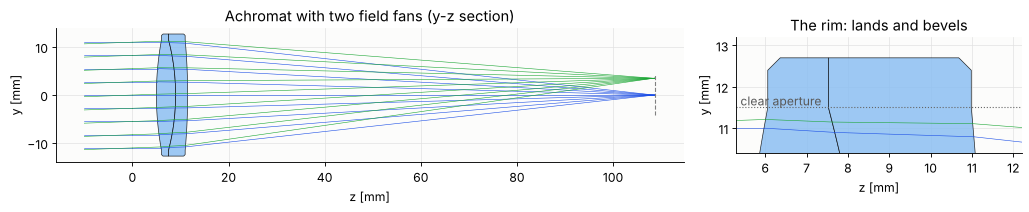

In [2]:
achromat = rt.System([rt.Surface(np.inf, 5.0, semi_diameter=11.0),
                      rt.Surface(62.8, 4.0, n_after=1.5168, semi_diameter=11.5),
                      rt.Surface(-45.7, 2.5, n_after=1.6727, semi_diameter=11.5),
                      rt.Surface(-128.2, 95.0, n_after=1.0, semi_diameter=11.5)],
                     0, 550e-6, field_angle=np.radians(2.0)).at_paraxial_focus()
print("efl {:.2f} mm, elements {}".format(achromat.paraxial().efl, achromat.elements()))

t = time.time()
model = cad.system_model(achromat, n_rays=9, ray_start=10.0,
                         mechanics=cad.Mechanics(margin=1.2, bevel=0.3))
print("built in {:.2f} s".format(time.time() - t))
for lens in model.lenses:
    kinds = sorted({f.geom_type.name for f in lens.faces()})
    print("{}: {:7.1f} mm³, valid {}, faces {}".format(lens.label, lens.volume, lens.is_valid, kinds))

fig, axs = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [2.2, 1]})
cad.plot_section(model, axs[0])
axs[0].set_title("Achromat with two field fans (y-z section)")
cad.plot_section(model, axs[1])
axs[1].set_xlim(5.3, 12.2)
axs[1].set_ylim(10.4, 13.2)
axs[1].axhline(11.5, color="0.4", ls=":", lw=1)
axs[1].text(5.4, 11.55, "clear aperture", color="0.35")
axs[1].set_title("The rim: lands and bevels")
fig.tight_layout()

The optical faces are `SPHERE` surfaces, the lands `PLANE`, the rim a
`CYLINDER` and the bevels `CONE`s: nothing is tessellated, so the CAD
system measures the same radii as the prescription. The solid of the crown
lens can be checked against an integral over its section: the lens volume
inside the clear aperture, the land annulus out to the rim, minus the ring
that the front bevel removes (a triangle of legs 0.3 mm swept around the
rim).

In [3]:
def sag(R, r):
    return R - np.sign(R)*np.sqrt(R**2 - r**2)

rc, rm, b = 11.5, 12.7, 0.3
r = np.linspace(0, rc, 20001)
thick = 4.0 + sag(-45.7, r) - sag(62.8, r)
V = np.trapezoid(2*np.pi*r*thick, r) + np.pi*(rm**2 - rc**2)*thick[-1] - 2*np.pi*(rm - b/3)*b**2/2
print("L1a: CAD {:.4f} mm³, integral {:.4f} mm³".format(model.lenses[0].volume, V))

L1a: CAD 1268.4123 mm³, integral 1268.4123 mm³


`export_step()` writes the model as one assembly: `lenses`, `rays` (one
polyline per ray, coloured by field) and the image plane, all in
millimetres whatever the units of the system. With `rays="tube"` the rays
become thin cylinders instead, which show up in renderings and can take
part in interference checks; `pupil` picks the rays (a meridional fan
`"y"`, `"x"`, both, a `"ring"` at the rim of the pupil or explicit
coordinates).

In [4]:
path = os.path.join(OUT, "achromat.step")
cad.export_step(model, path)
tubes = cad.system_model(achromat, n_rays=12, pupil="ring", rays="tube", ray_radius=0.05,
                         mechanics=cad.Mechanics(margin=1.2, bevel=0.3))
path_tubes = os.path.join(OUT, "achromat_tubes.step")
cad.export_step(tubes, path_tubes)
for p in (path, path_tubes):
    print("{}: {:.0f} kB".format(os.path.basename(p), os.path.getsize(p)/1e3))

achromat.step: 129 kB
achromat_tubes.step: 1147 kB


## 2. Between clear aperture and rim

The clear aperture is what the optics needs; the rim is what the mount
needs. `Mechanics` sets the rim semi-diameter directly (`semi_diameter`) or
as a `margin` over the largest clear semi-diameter of the element, and
`land` decides what fills the annulus between them:

- `"flat"`: a plane perpendicular to the axis at the height of the
  clear aperture rim. It is the seat for a retaining ring or a spacer, and
  it is what an optical shop grinds anyway when the lens is edged.
- `"extend"`: the optical surface goes on to the rim, as in many
  catalogue lenses.

The flat land meets the optical surface at an angle of 180° minus the
slope angle of the surface, an obtuse edge that needs no bevel. The edges
at the rim are the ones that chip, so the bevels go there. A lens whose
surfaces would cross before the rim (a strong biconvex lens with extended
surfaces and a large margin) cannot be built; `system_model()` refuses it
with the edge thickness that it found. With flat lands the same lens can
have a rim of any size.

extended surfaces with a 4 mm margin: Edge thickness -1.93 below 0.1 at semi-diameter 13.0


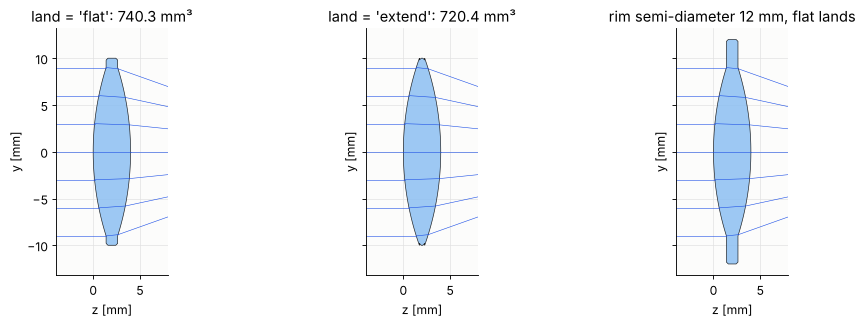

In [5]:
lens = rt.System([rt.Surface(30.0, 4.0, n_after=1.5168, semi_diameter=9.0),
                  rt.Surface(-30.0, 40.0, n_after=1.0, semi_diameter=9.0)], 0, 550e-6)
fig, axs = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
for ax, land in zip(axs[:2], ["flat", "extend"]):
    m = cad.system_model(lens, n_rays=7, ray_start=4, image_plane=False,
                         mechanics=cad.Mechanics(margin=1.0, land=land, bevel=0.2,
                                                 ))
    cad.plot_section(m, ax)
    ax.set_xlim(-4, 8)
    ax.set_title("land = {!r}: {:.1f} mm³".format(land, m.lenses[0].volume))
try:
    cad.system_model(lens, rays=None, mechanics=cad.Mechanics(margin=4.0, land="extend"))
except ValueError as err:
    print("extended surfaces with a 4 mm margin:", str(err).split(" between")[0])
m = cad.system_model(lens, n_rays=7, ray_start=4, image_plane=False,
                     mechanics=cad.Mechanics(semi_diameter=12.0, bevel=0.2))
cad.plot_section(m, axs[2])
axs[2].set_xlim(-4, 8)
axs[2].set_title("rim semi-diameter 12 mm, flat lands")
fig.tight_layout()

## 3. A Cooke triplet in a barrel

With `mount=cad.Mount()` the model gets a first cut of the mechanics of a
coaxial lens: a barrel whose bore is the largest rim plus a radial
clearance, a retaining ring in front of the first and behind the last
element, spacers between the elements and an aperture plate at a stop that
lies in air. The rings and spacers are built as solids of revolution and
then cut by the lens solids, so they sit exactly on the lands and bevels.
Their bore starts a little outside the clear aperture of the lens they
touch (`spacer_clearance`) and runs conically from one lens to the next:
the edge of a bundle of straight rays between two surfaces is a convex
function of z and stays inside that cone.

The triplet is the classic f/4.5 Cooke design (efl about 47 mm, ±10°),
whose stop sits in the air space between the negative lens and the rear
crown.

built in 0.23 s
part        volume [mm³]
L1              242.1
L2              232.2
L3              237.5
barrel         2304.1
ring_front      177.4
spacer_1        559.2
spacer_2a       227.7
spacer_2b       454.1
ring_back       330.3
stop             44.4


largest overlap of mount and lenses: 0.0e+00 mm³
closest approach of a ring or spacer to a traced ray: 0.70 mm


True

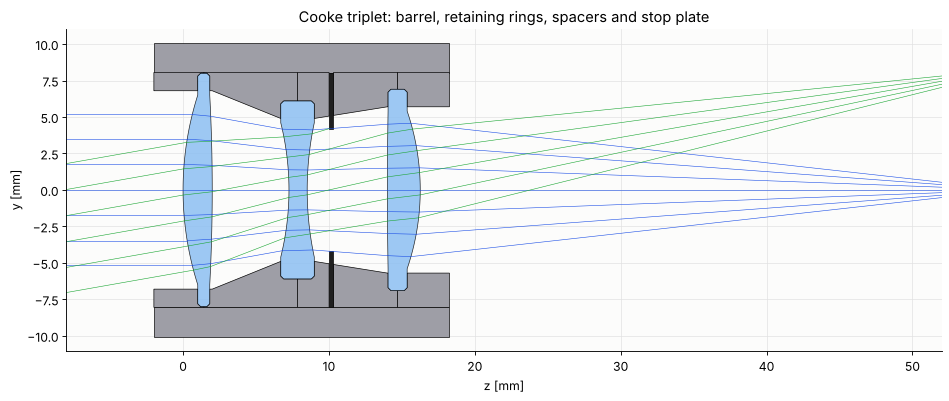

In [6]:
triplet = rt.System([rt.Surface(21.48, 2.0, n_after=1.6204, semi_diameter=6.5),
                     rt.Surface(-124.1, 5.26, n_after=1.0, semi_diameter=6.5),
                     rt.Surface(-19.1, 1.25, n_after=1.6034, semi_diameter=4.6),
                     rt.Surface(22.0, 1.5, n_after=1.0, semi_diameter=4.6),
                     rt.Surface(np.inf, 4.0, semi_diameter=4.2),
                     rt.Surface(328.9, 2.25, n_after=1.6204, semi_diameter=5.4),
                     rt.Surface(-16.7, 43.0, n_after=1.0, semi_diameter=5.4)],
                    4, 550e-6, field_angle=np.radians(10)).at_paraxial_focus()
t = time.time()
cooke = cad.system_model(triplet, n_rays=7, ray_start=8, mechanics=cad.Mechanics(margin=1.5, bevel=0.2),
                         mount=cad.Mount(wall=2.0, ring_length=2.0, spacer_clearance=0.3))
print("built in {:.2f} s".format(time.time() - t))
print("part        volume [mm³]")
for part in cooke.lenses + cooke.mount:
    print("{:10s} {:10.1f}".format(part.label, part.volume))

clash = max((p & l).volume if (p & l) is not None else 0.0 for p in cooke.mount for l in cooke.lenses)
gap = min(p.distance_to(r) for p in cooke.mount if p.label not in ("barrel", "stop") for r in cooke.rays)
print("largest overlap of mount and lenses: {:.1e} mm³".format(clash))
print("closest approach of a ring or spacer to a traced ray: {:.2f} mm".format(gap))

fig, ax = plt.subplots(figsize=(12, 5))
cad.plot_section(cooke, ax)
ax.set_xlim(-8, 52)
ax.set_title("Cooke triplet: barrel, retaining rings, spacers and stop plate")
fig.tight_layout()
cad.export_step(cooke, os.path.join(OUT, "cooke_triplet.step"))

The negative lens has the smallest rim, so it sits in the bore with a
radial gap; the spacers on both sides reach around its rim and centre it.
In a real barrel the bore would step down to each lens with a fit, and the
retaining rings would be threaded; the generated parts are a starting
point that already has the right axial positions and contact faces.

## 4. Freeforms, tilted elements and a fold mirror

Not every slab is a solid of revolution. Surfaces with a `sag_xy(x, y)`
(`ZernikeSurface`, `qaspheres.Q2DSurface`, `freeform.TabulatedSurface`) and
slabs whose surfaces are tilted or decentred against each other are cut
from a cylinder along the axis of their first surface: by a B-spline face
through the sag on a grid, or by the revolved section of a rotationally
symmetric surface. Lands and bevels work as before. On a freeform the rim
height changes around the circumference, so the flat land is put at the
point of the rim that lies farthest towards air, and a short step joins it
to the optical face.

The example has a plate with a Zernike astigmatism and trefoil departure,
a window tilted by 8° and a fold mirror with a freeform figure on a
coordinate break of 45°. The mirror gets a substrate with a flat back
`mirror_thickness` behind its face.

built in 0.58 s
L1:   850.6 mm³, faces ['BSPLINE', 'CONE', 'CYLINDER', 'PLANE']
L2:   396.2 mm³, faces ['CONE', 'CYLINDER', 'PLANE']
M3:  1257.5 mm³, faces ['BSPLINE', 'CONE', 'CYLINDER', 'PLANE']


True

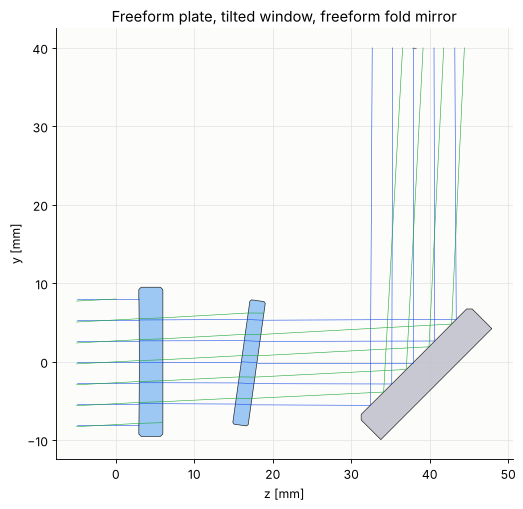

In [7]:
fold = rt.System([rt.Surface(np.inf, 3.0, semi_diameter=8.0),
                  rt.ZernikeSurface(np.inf, 3.0, zernike={5: 0.05, 10: 0.03}, norm_radius=8.0,
                                    n_after=1.5168, semi_diameter=8.0),
                  rt.Surface(np.inf, 10.0, n_after=1.0, semi_diameter=8.0),
                  rt.Surface(np.inf, 2.0, n_after=1.5168, semi_diameter=7.0, tilt=(np.radians(8), 0, 0)),
                  rt.Surface(np.inf, 20.0, n_after=1.0, semi_diameter=7.0, tilt=(np.radians(8), 0, 0)),
                  rt.CoordinateBreak(tilt=(np.pi/4, 0, 0)),
                  rt.ZernikeSurface(np.inf, 0.0, zernike={5: 0.02}, norm_radius=8.0, mirror=True,
                                    semi_diameter=8.0),
                  rt.CoordinateBreak(tilt=(np.pi/4, 0, 0), thickness=-40.0)],
                 0, 550e-6, field_angle=np.radians(3.0))
t = time.time()
folded = cad.system_model(fold, n_rays=7, ray_start=5,
                          mechanics={0: cad.Mechanics(margin=1.5, bevel=0.3),
                                     1: cad.Mechanics(margin=1.0, bevel=0.2),
                                     2: cad.Mechanics(margin=2.0, mirror_thickness=4.0, bevel=0.5)})
print("built in {:.2f} s".format(time.time() - t))
for part in folded.lenses:
    print("{}: {:7.1f} mm³, faces {}".format(part.label, part.volume,
                                            sorted({f.geom_type.name for f in part.faces()})))
fig, ax = plt.subplots(figsize=(8, 6.5))
cad.plot_section(folded, ax)
ax.set_title("Freeform plate, tilted window, freeform fold mirror")
fig.tight_layout()
cad.export_step(folded, os.path.join(OUT, "fold.step"))

The trefoil term of the plate bends the rays out of the meridional plane,
so the section shows their projection. The Zernike terms average to zero
over a circle, so without the land the plate would have exactly the volume
of a 3 mm disk; the land and the bevels change that by what they add and
remove, which the tests of `pyoptics.cad` check against an integral over
the sag.

## 5. A Fresnel lens

A `fresnel.FresnelSurface` (notebook [51 (Fresnel lenses)](51_fresnel_lenses.ipynb))
has a stepped section: facets that follow the parent surface and risers
between them. The CAD section uses its `section()` with a B-spline per
facet and straight risers, so the facets keep their curvature and the
risers their draft angle.

25 faces, 699.5 mm³


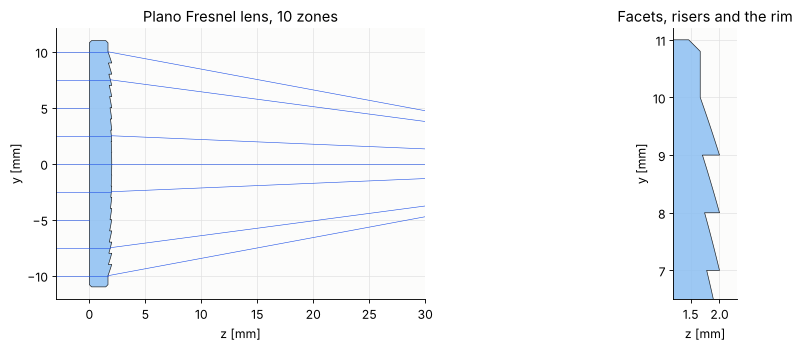

In [8]:
fresnel = FresnelSurface(-30.0, n_zones=10, radius=10.0, n_after=1.0, semi_diameter=10.0,
                         thickness=60.0)
fl = rt.System([rt.Surface(np.inf, 2.0, n_after=1.5, semi_diameter=10.0), fresnel], 0, 550e-6)
fm = cad.system_model(fl, n_rays=9, ray_start=3, image_plane=False,
                      mechanics=cad.Mechanics(margin=1.0, bevel=0.2))
print("{} faces, {:.1f} mm³".format(len(fm.lenses[0].faces()), fm.lenses[0].volume))
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [3, 1]})
cad.plot_section(fm, axs[0])
axs[0].set_xlim(-3, 30)
axs[0].set_title("Plano Fresnel lens, 10 zones")
cad.plot_section(fm, axs[1], rays=False)
axs[1].set_xlim(1.2, 2.3)
axs[1].set_ylim(6.5, 11.2)
axs[1].set_title("Facets, risers and the rim")
fig.tight_layout()

## Summary

- `cad.system_model()` turns a `raytrace.System` into lens solids, mirror
  substrates, ray fans and the image plane; `cad.export_step()` writes them
  as one STEP assembly in millimetres with names and colours.
- Spheres and planes are exact surfaces, aspheres B-splines within
  `tolerance` (0.1 µm by default), freeforms B-spline faces.
- `Mechanics` per element sets the rim, flat or extended lands, bevels on
  edges in air, mirror substrates and the smallest edge thickness.
- `Mount` adds a barrel, retaining rings, spacers and a stop plate for
  coaxial lenses, cut to the lens solids and clear of the traced rays.
- `cad.plot_section()` draws a section of the model, a quick check before
  the STEP file goes to the CAD system.

In [9]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 5 s
